# Lecture 16, Downscaling: the problem, the data and choosing a method

> Why a global climate model is not enough for a catchment, what data we have, and how to pick a scheme

Lectures 13 and 14 showed how CMIP produces climate projections and why they differ. A catchment engineer cannot
use those numbers directly: a CMIP grid cell is larger than most river basins, and the model's rainfall and temperature
are systematically wrong when compared with gauges. **Downscaling** is the set of methods that closes this gap.
Lectures 16 to 23 cover them one by one. This first lecture sets the stage:

- Why is a GCM cell value not a catchment value, and how large is the gap?
- What are GCM, reanalysis, RCM and observed data, and why do the files look so different (units, calendars, grids)?
- What families of downscaling exist, and which question does each one answer?
- What is the one assumption (stationarity) that all statistical methods share?
- Given a project, how do you choose a scheme?

By the end of this lecture you should be able to:

1. compute the area of a grid cell and compare it with a catchment, and name the three parts of the gap (scale, bias, timing),
2. convert GCM precipitation flux to mm/day and temperature to $^\circ$C, and handle a 360-day or 365-day calendar,
3. subset a gridded dataset to a catchment with `xarray` and compare model, reanalysis and observations,
4. explain **perfect prognosis** versus **model-output statistics** and the assumption of **stationarity**,
5. use a decision guide to choose between delta change, bias correction, regression, weather generator, weather typing, temporal and spatial downscaling.

A spreadsheet with the same numbers is in `data/downscaling/lec16/lec16_worked_examples.xlsx`. **All data in this lecture are synthetic**:
they are generated in Section 6 to look like model, reanalysis and gauge data, with the problems built in on purpose.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy xarray cftime

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import xarray as xr
plt.rcParams["figure.dpi"] = 100

# 1) The problem: a scale gap and a bias

A global climate model (GCM) divides the atmosphere into grid cells roughly $1^\circ$ to $2.5^\circ$ wide, 100 to 280 km. Every output value of a cell, for example daily precipitation, is an **average over the whole cell**. A catchment of 1000 km$^2$ is much smaller than that. How much smaller?

### Area of a grid cell

On a sphere of radius $R$ a small patch between latitudes $\varphi$ and $\varphi+d\varphi$ and longitudes $\lambda$ and $\lambda+d\lambda$ has area $dA = R^2\cos\varphi\,d\varphi\,d\lambda$ ($R\,d\varphi$ is the north&ndash;south side, $R\cos\varphi\,d\lambda$ the east&ndash;west side, which shrinks towards the poles). Integrating over a cell from $\varphi_1$ to $\varphi_2$ and over a longitude width $\Delta\lambda$ (in radians):

$$A = R^2\,\Delta\lambda\int_{\varphi_1}^{\varphi_2}\cos\varphi\,d\varphi = R^2\,\Delta\lambda\,\left(\sin\varphi_2-\sin\varphi_1\right).$$

*Check:* the whole sphere has $\Delta\lambda=2\pi$ and $\sin(\pi/2)-\sin(-\pi/2)=2$, so $A=4\pi R^2$. The code below confirms this and then evaluates cells of different products at the latitude of a Himalayan catchment ($31.75^\circ$N).

In [3]:
R = 6371.0   # Earth radius [km]

def cell_area(lat_c, size_lat, size_lon, R=R):
    """Area [km2] of a latitude-longitude cell centred at lat_c; sizes in degrees."""
    phi1, phi2 = np.deg2rad(lat_c - size_lat / 2), np.deg2rad(lat_c + size_lat / 2)
    return R**2 * np.deg2rad(size_lon) * (np.sin(phi2) - np.sin(phi1))

print("whole sphere:", cell_area(0, 180, 360), "km2   4 pi R^2 =", 4 * np.pi * R**2)

products = [("CMIP6 GCM, typical", 2.5), ("CMIP6 GCM, fine", 1.0), ("CORDEX South Asia, coarse", 0.44),
            ("ERA5 / NEX-GDDP-CMIP6 / IMD rain", 0.25)]
catch = 1000.0   # catchment area [km2]
tab = pd.DataFrame([(n, s, cell_area(31.75, s, s), catch / cell_area(31.75, s, s)) for n, s in products],
                   columns=["product", "cell size [deg]", "cell area [km2]", "catchment area / cell area"])
print(tab.round({"cell area [km2]": 0, "catchment area / cell area": 3}).to_string(index=False))

whole sphere: 510064471.90978825 km2   4 pi R^2 = 510064471.90978825
                         product  cell size [deg]  cell area [km2]  catchment area / cell area
              CMIP6 GCM, typical             2.50          65707.0                       0.015
                 CMIP6 GCM, fine             1.00          10514.0                       0.095
       CORDEX South Asia, coarse             0.44           2036.0                       0.491
ERA5 / NEX-GDDP-CMIP6 / IMD rain             0.25            657.0                       1.522


A $2.5^\circ$ cell at $31.75^\circ$N is about $278\times236$ km, some 65,000 km$^2$, and the catchment covers 1.5 % of it (ratio 0.015 in the table; a ratio above 1 means the catchment spans several cells). Inside that cell the mountains, the valley, the windward and lee slopes are all averaged into one number.

The gap between "what the model gives" and "what the hydrologist needs" has **three parts**:

| Part | What goes wrong | Example |
|:--|:--|:--|
| **Scale (representativeness)** | A cell mean is not the value at the catchment: terrain, altitude and local rainfall gradients are smoothed out | The cell sits at 1700 m, the catchment at 2250 m, so the model is warmer; the rain-shadow ridge is invisible |
| **Bias** | The model's climate differs systematically from the observed one, even after allowing for scale | Monsoon peak a few weeks late, too many very light rain days, heavy rain too weak |
| **Timing (internal variability)** | A free-running GCM simulates *a* possible weather, not the real weather of 2005 | Its rainy days do not coincide with real rainy days; only its statistics are meaningful |

For a *bias* we use two simple definitions. For a quantity that can be positive or negative (temperature) the **additive bias** is $b=\overline{x}_\mathrm{model}-\overline{y}_\mathrm{obs}$ [same unit]; for precipitation, which cannot be negative, we use the **multiplicative bias** $\overline{x}_\mathrm{model}/\overline{y}_\mathrm{obs}$ [dimensionless; 1 means no bias].

### What does the hydrological model need?

A lumped or distributed model such as those of Lectures 7 and 8 needs a **time series at the catchment**, usually daily (or hourly for small, fast basins) precipitation and temperature (for evaporation), with the right *mean*, the right *number of wet days*, the right *intensity of heavy rain*, the right *seasonal timing* and consistency between variables. This matters because catchments respond **nonlinearly**: if runoff only starts when rain exceeds the infiltration capacity, then 20 mm in one storm produces flood runoff, while 20 mm spread as 0.5 mm drizzle over 40 days produces almost none, although the totals are identical. A model with the right annual total but the wrong rain distribution gives the wrong flood and the wrong recharge. Downscaling is therefore not only "making the map finer"; it is making the *distribution* of local weather right.

# 2) The data: GCM, reanalysis, RCM and observations

| Source | What it is | Typical resolution | What it is good for in downscaling | Caution |
|:--|:--|:--|:--|:--|
| **GCM** (CMIP6) | Global model run with prescribed forcing (`historical`, then a scenario). **Free-running**: it is not told what the weather did on a given day | 100&ndash;250 km, daily or monthly | The only source of future projections; large-scale predictors | Own weather; biased; coarse |
| **Reanalysis** (ERA5, MERRA-2, NCEP/NCAR) | A weather model run through the past with **data assimilation** of observations, so the large-scale weather follows the real weather day by day | 0.25&deg; (ERA5) to 2.5&deg; (NCEP/NCAR), 1940 or 1979 to now | **Predictors** (pressure, winds, humidity, temperature) that really coincide with observed local weather, used to *fit* statistical relations | Its precipitation is a model product, not a measurement; surface fields carry model bias |
| **RCM** (CORDEX) | A regional model nested in a GCM or reanalysis, run at finer grid | 0.44&deg; to 0.11&deg; (about 50 to 12 km) | Physically consistent fine-scale fields; terrain and mesoscale rainfall | Inherits boundary errors from the GCM and has its own bias; expensive; usually still needs bias correction |
| **Observations** (IMD stations, IMD gridded rainfall, gauges) | Measurements, or interpolated products from them | point or 0.25&deg; | The **target** for calibration and for judging bias | Sparse in mountains; gridded products smooth too; gauge errors |

The key difference is **synchronisation with the real weather**. A reanalysis tracks real weather, so a day of heavy reanalysis rain is usually a day of heavy gauge rain. A GCM historical run does not: the model's monsoon depression of 12 July 2005 never happened. This one fact decides which statistical methods are possible (Section 3), and the hands-on part of this lecture measures it.

### File formats, names, calendars and units

- **Format.** CMIP6, CORDEX, ERA5 and NEX-GDDP-CMIP6 come as **NetCDF** files following the CF conventions: named dimensions (`time`, `lat`, `lon`), coordinate variables, and attributes (`units`, `long_name`, `calendar`). `xarray` reads them directly (Lecture 15).
- **File name** (CMIP6 pattern): `variable_table_model_experiment_variant_grid_period.nc`, for example `pr_day_<model>_ssp245_r1i1p1f1_gn_20150101-20641230.nc` (placeholder model name). The final date `1230` already hints at a 360-day calendar.
- **Variables.** `pr` precipitation, `tas` near-surface air temperature, `tasmax`, `tasmin`, `psl` sea-level pressure, `huss` specific humidity, `uas`, `vas` winds.
- **Calendars.** Models need not use the real calendar. `standard` has leap days; `noleap` (`365_day`) never has 29 February (several models, for example CESM2 and NorESM2); `360_day` has twelve 30-day months (Hadley Centre models); some use `proleptic_gregorian`. `xarray` handles the non-standard ones with `cftime` dates. Day-by-day alignment with observations therefore needs care, and a "total" must use the number of days of the calendar.
- **Units.** GCM `pr` is a **flux in kg m$^{-2}$ s$^{-1}$**, `tas` is in **kelvin**. ERA5 gives total precipitation as an **accumulated depth in metres**. Observations are in mm/day and $^\circ$C. Longitude may run 0&ndash;360 or $-180$&ndash;180, and latitude may be ascending or descending.

### From flux to depth

Water has density $\rho_w=1000$ kg m$^{-3}$. A mass of 1 kg spread over 1 m$^2$ has volume $1/1000$ m$^3$, so its depth is $10^{-3}$ m $=1$ mm: **1 kg m$^{-2}$ of water is 1 mm**. A flux $P_f$ [kg m$^{-2}$ s$^{-1}$] is therefore $P_f$ mm per second, and a day has 86 400 s:

$$P\,[\mathrm{mm\,day^{-1}}] = P_f\times 86\,400 .$$

*Check:* $P_f=10^{-4}$ kg m$^{-2}$ s$^{-1}$ gives 8.64 mm/day, a wet monsoon day. To get a river-flow equivalent, a depth $P$ [mm/day] over an area $A$ [km$^2$] is $P\cdot10^{-3}$ m $\times A\cdot10^{6}$ m$^2$ $=10^{3}PA$ m$^3$ per day, so $Q = 10^{3}PA/86\,400 = PA/86.4$ m$^3$ s$^{-1}$. For 10 mm/day over 1000 km$^2$ this is 115.7 m$^3$ s$^{-1}$ (all of the rain, with no losses).

# 3) Families of downscaling

**Dynamical downscaling** runs a regional climate model (RCM) with fine grid inside the GCM; the physics does the downscaling. It gives physically consistent, multi-variable fields, but costs a great deal of computing, inherits the errors of the driving GCM and is itself biased. **Statistical downscaling** instead learns a relation between large-scale information and the local weather from data, and applies it to the model. It is cheap and can target a station, but it needs observations and assumes the relation still holds in the future (Section 4). In practice the two are combined: RCM output is also bias-corrected.

Statistical methods differ in *what output they give*, and that is how to choose among them:

| Scheme | Idea | Use it when you need | Lecture |
|:--|:--|:--|:--|
| **Bias correction** (scaling, quantile mapping) | Compare the model's historical distribution with the observed one and correct the model output | the model's own series, made unbiased; the simplest, most used option | 18 |
| **Delta change** | Keep the observed series; apply the model's *change* between periods | design values from the observed record shifted to the future | 18 |
| **Regression** (transfer function) | $y=f(\mathbf{x})$ from large-scale predictors, fitted with reanalysis | a local daily series that responds to changes in circulation and temperature (works well for temperature, poorly for rain) | 19, 20 |
| **Weather generator** | A stochastic model of the local weather whose parameters are changed according to the GCM | many equally likely series, risk analysis, changed variability | 21 |
| **Weather typing** | Classify circulation into types and link types to local rain | rain tied to circulation patterns | 22 |
| **Temporal downscaling** | Disaggregate daily to hourly (or monthly to daily) | sub-daily rain for small and urban catchments | 22 |
| **Spatial downscaling** | Refine a coarse grid to a fine grid | gridded input for distributed models | 23 |

The first four give a time series *at a site*; the last two refine the *time step* or the *grid* of a series that has already been corrected, so they come **after** another scheme.

### Perfect prognosis versus model-output statistics

Let $y$ be the local variable (rain or temperature at the catchment) and $\mathbf{x}$ the large-scale information. There are two ways to calibrate a statistical link, and the difference is *which $\mathbf{x}$ is used to fit it*.

**Perfect prognosis (PP).** Fit $y=f(\mathbf{x}_\mathrm{rea})+\varepsilon$ using **reanalysis** predictors, which are synchronised with the observed $y$, so the pairs $(\mathbf{x}_t,y_t)$ are genuine day-by-day pairs and an ordinary regression is meaningful. Then *replace* $\mathbf{x}_\mathrm{rea}$ by the GCM's $\mathbf{x}_\mathrm{gcm}$ in the future. The name says it: we pretend that the GCM predictor is "perfect", i.e. statistically like the reanalysis. This needs predictors the GCM simulates well (large-scale circulation, not rain) and a relation $f$ that does not change.

**Model-output statistics (MOS).** Fit the link directly between the **model's own** historical output and the observation, $y\approx g(x_\mathrm{gcm})$. Because the model's days do not coincide with real days, the pairs cannot be matched in time; the only link that can be learned is between the **distributions**, $y = F_\mathrm{obs}^{-1}\big(F_\mathrm{gcm}(x)\big)$, where $F$ is a cumulative distribution function (quantile mapping, Lecture 18). The model's bias is part of what is learned and is therefore removed, but the sequence of weather is the model's, not the real one.

| | PP | MOS |
|:--|:--|:--|
| Predictor used for fitting | reanalysis (synchronised with observations) | GCM historical run itself |
| What is matched | day-to-day pairs | distributions |
| GCM bias in the predictor | not corrected (must be small) | corrected |
| Typical schemes | regression, weather typing | bias correction (quantile mapping) |

A weather generator sits between the two: its parameters are fitted to observations, and the GCM only supplies *changes* in those parameters.

# 4) The key assumption: stationarity

Every statistical scheme fits a rule on the **past** (a regression coefficient, a bias, a quantile map) and uses it in the **future**. Calling the rule $f(\mathbf{x};\theta)$ with parameters $\theta$, **stationarity** is the assumption that $\theta_\mathrm{future}=\theta_\mathrm{past}$. It cannot be proved with the data we have, because the future is exactly what is not observed. The harm of violating it can still be seen in a one-line model.

Suppose the true local warming is $\Delta T$, but the model, whose response is damped by a factor $s<1$ (for example it smooths the mountain), warms by $s\,\Delta T$. In the historical period the model mean is $\overline{x}$ and the observed mean is $\overline{y}$, and a simple **mean-shift** correction uses $c=\overline{y}-\overline{x}$, so $\hat y = x + c$. In the future $\overline{\hat y}_\mathrm{fut}=\overline{x}+s\Delta T+c = \overline{y}+s\Delta T$, whereas the truth is $\overline{y}+\Delta T$. The error is

$$\text{error}=\overline{\hat y}_\mathrm{fut}-\overline{y}_\mathrm{fut} = (s-1)\,\Delta T .$$

The correction $c$ was learned when $\Delta T\approx0$; it silently assumes that the model's bias does not depend on the climate state. For $s=0.8$ and $\Delta T=3$ K, the corrected projection misses $0.6$ K of warming, a fifth of the signal.

In [4]:
rng = np.random.default_rng(1)
n, dT, s = 36500, 3.0, 0.8                            # days, true local warming [K], model damping factor
y_hist = 15 + 4 * rng.standard_normal(n)             # observed local temperature [degC]
x_hist = 12 + 4 * rng.standard_normal(n)             # model temperature in the same period (own weather, own bias)
c = y_hist.mean() - x_hist.mean()                    # mean-shift correction learned in the past

y_fut = 15 + dT + 4 * rng.standard_normal(n)         # what would really happen
x_fut = 12 + s * dT + 4 * rng.standard_normal(n)     # the damped model
y_hat = x_fut + c                                    # corrected projection
print(f"correction c = {c:.2f} K")
print(f"true warming      : {y_fut.mean() - y_hist.mean():.2f} K")
print(f"corrected model   : {y_hat.mean() - y_hist.mean():.2f} K")
print(f"error (s-1)*dT    : {(s - 1) * dT:.2f} K   from the formula")

correction c = 2.95 K
true warming      : 3.04 K
corrected model   : 2.39 K
error (s-1)*dT    : -0.60 K   from the formula


So the question to ask of any statistical scheme is: *would the rule I learned still hold if the climate were 3 K warmer?* The usual safeguards are (i) a **split-sample test**: fit on the cooler (or drier) half of the record and test on the warmer half; (ii) choosing **predictors that carry the physical signal** (for example large-scale temperature rather than rain); and (iii) checking **against an RCM or the model's own future** whether the corrected change is plausible. Delta change keeps the model's *change* and uses the observations only as a baseline, which is why it is more robust for the mean but cannot change how often it rains.

# 5) Choosing a scheme: a decision guide

No scheme is best in general: it depends on **what the impact model needs as input**. The guide below asks five questions in order; the first "yes" decides the core scheme, and two further needs (sub-daily output, a fine grid) add a step. It is a guide for a first choice, not a rule: the available data and the time you have also matter. The spreadsheet sheet `Method_guide` implements the same logic.

1. Is a **change factor** enough (observed record scaled by a projected change)? Then **delta change**.
2. Is a **corrected model distribution** enough, with no need for day-to-day agreement with real days (monthly water balance, seasonal flow)? Then **bias correction**.
3. Do **predictors with real skill** exist (for example $|r|\ge0.5$ in the reanalysis period)? Then **regression downscaling** (PP).
4. Do you need **many equally likely series** or changed variability and extremes (risk, drought)? Then a **weather generator**.
5. Is the rain **tied to circulation types**? Then **weather typing** with a stochastic model.
6. Otherwise: use **RCM output** (dynamical downscaling) and bias-correct it.

*Add-ons:* sub-daily output means **temporal downscaling** after the above; a fine grid or many sites means **spatial downscaling**.

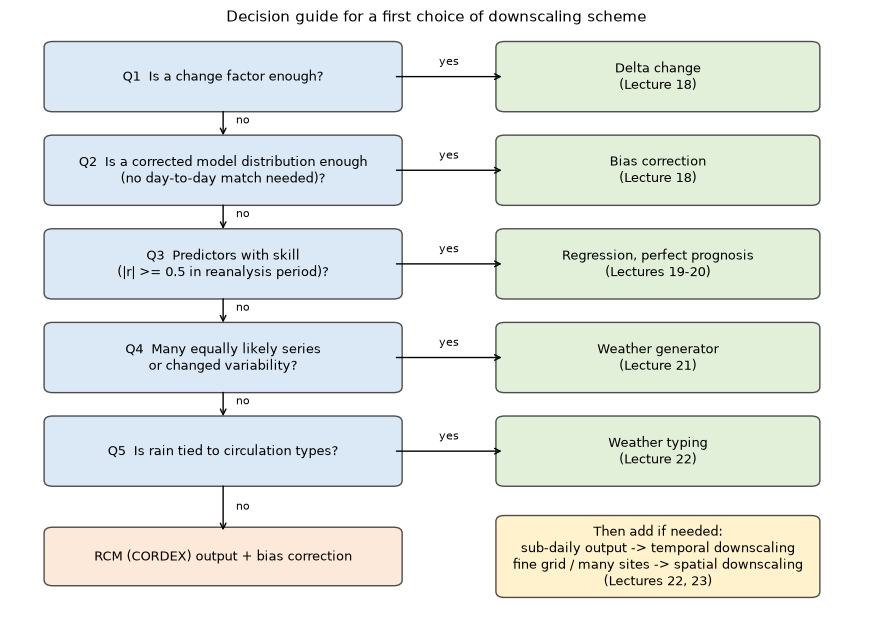

                                                   project       core scheme                add-ons
               Seasonal reservoir inflow change, 2070-2100      Delta change                   none
   Monthly water balance, lumped model, corrected GCM rain   Bias correction                   none
Daily temperature for a crop model (strong predictor link)   Regression (PP)                   none
        Drought risk: thousands of 30-year rainfall series Weather generator                   none
                      Rainfall linked to circulation types    Weather typing                   none
                Urban drainage design: hourly rain, 20 km2 Weather generator + temporal downscaling
                          Distributed model on a 1 km grid   Bias correction  + spatial downscaling


In [5]:
def recommend(delta_only, dist_ok, r_pred, many, circ, subdaily, grid, r_min=0.5):
    """Same decision order as the flow chart and the Method_guide sheet."""
    if delta_only:    core = "Delta change"
    elif dist_ok:     core = "Bias correction"
    elif r_pred >= r_min: core = "Regression (PP)"
    elif many:        core = "Weather generator"
    elif circ:        core = "Weather typing"
    else:             core = "RCM output + bias correction"
    add = [t for flag, t in ((subdaily, "temporal downscaling"), (grid, "spatial downscaling")) if flag]
    return core, ("+ " + ", ".join(add)) if add else "none"

# --- the flow chart
fig, ax = plt.subplots(figsize=(11, 7.6)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0.0, 1.0)
qs = ["Q1  Is a change factor enough?", "Q2  Is a corrected model distribution enough\n(no day-to-day match needed)?",
      "Q3  Predictors with skill\n(|r| >= 0.5 in reanalysis period)?", "Q4  Many equally likely series\nor changed variability?",
      "Q5  Is rain tied to circulation types?"]
outs = ["Delta change\n(Lecture 18)", "Bias correction\n(Lecture 18)", "Regression, perfect prognosis\n(Lectures 19-20)",
        "Weather generator\n(Lecture 21)", "Weather typing\n(Lecture 22)"]
ys = [0.92, 0.76, 0.60, 0.44, 0.28]
def box(xc, yc, w, h, text, fc):
    ax.add_patch(mpatches.FancyBboxPatch((xc - w / 2, yc - h / 2), w, h, boxstyle="round,pad=0.01", fc=fc, ec="0.3"))
    ax.text(xc, yc, text, ha="center", va="center", fontsize=9)
for i, (q, o, y) in enumerate(zip(qs, outs, ys)):
    box(0.25, y, 0.40, 0.10, q, "#dbe9f6")
    box(0.76, y, 0.36, 0.10, o, "#e2f0d9")
    ax.annotate("", xy=(0.58, y), xytext=(0.45, y), arrowprops=dict(arrowstyle="->"))
    ax.text(0.515, y + 0.02, "yes", ha="center", fontsize=8)
    if i < 4:
        ax.annotate("", xy=(0.25, ys[i + 1] + 0.055), xytext=(0.25, y - 0.055), arrowprops=dict(arrowstyle="->"))
        ax.text(0.265, (y + ys[i + 1]) / 2, "no", fontsize=8)
ax.annotate("", xy=(0.25, 0.10 + 0.04), xytext=(0.25, 0.28 - 0.055), arrowprops=dict(arrowstyle="->"))
ax.text(0.265, 0.18, "no", fontsize=8)
box(0.25, 0.10, 0.40, 0.08, "RCM (CORDEX) output + bias correction", "#fde9d9")
box(0.76, 0.10, 0.36, 0.12, "Then add if needed:\nsub-daily output -> temporal downscaling\nfine grid / many sites -> spatial downscaling\n(Lectures 22, 23)", "#fff2cc")
ax.set_title("Decision guide for a first choice of downscaling scheme", fontsize=11)
plt.show()

# --- the same logic applied to example projects (these are the rows of the Method_guide sheet)
cases = [("Seasonal reservoir inflow change, 2070-2100", True, False, 0.3, False, False, False, False),
         ("Monthly water balance, lumped model, corrected GCM rain", False, True, 0.3, False, False, False, False),
         ("Daily temperature for a crop model (strong predictor link)", False, False, 0.9, False, False, False, False),
         ("Drought risk: thousands of 30-year rainfall series", False, False, 0.3, True, False, False, False),
         ("Rainfall linked to circulation types", False, False, 0.3, False, True, False, False),
         ("Urban drainage design: hourly rain, 20 km2", False, False, 0.3, True, False, True, False),
         ("Distributed model on a 1 km grid", False, True, 0.3, False, False, False, True)]
print(pd.DataFrame([(c[0], *recommend(*c[1:])) for c in cases], columns=["project", "core scheme", "add-ons"]).to_string(index=False))

# 6) Hands-on: a synthetic GCM, reanalysis and observation for one catchment

We now build a small world in which we **know the truth**, and make the three problems of Section 1 visible. All of it is synthetic; nothing is a real model or measurement.

- A fine "truth" surface on a $0.25^\circ$ grid: a ridge with a wet windward slope and high terrain (relative rainfall and elevation). The catchment is a $0.5^\circ$ box at $31.75^\circ$N, $77^\circ$E on that slope.
- **Observation:** daily rainfall (mm/day) and temperature ($^\circ$C) at the catchment, with a monsoon peaking in mid-July.
- **Reanalysis:** $1.25^\circ$ grid, real calendar, with its weather **synchronised** to the observation (correlated latent weather), smoother terrain, `tp` in metres and `t2m` in kelvin.
- **GCM:** $2.5^\circ$ grid, **360-day calendar**, its own independent weather, a monsoon that peaks about 2 weeks late, too many very light rain days and a smooth surface; `pr` in kg m$^{-2}$ s$^{-1}$ and `tas` in kelvin.

Rain on a day is generated from a latent Gaussian variable $z$ (wet if $\Phi(z)>1-p$, with a gamma-distributed amount when wet), so that "synchronised" simply means that the $z$ of two series are correlated. 2001&ndash;2010, 10 years. The cell below is the generator; skim it, you do not need to modify it. To use **real data**, replace `obs`, `rea` and `gcm` by series read from IMD gridded rainfall (observations), ERA5 (reanalysis) and a CMIP6 or NEX-GDDP-CMIP6 file (model), for example with `xr.open_dataset`.

In [6]:
# ---- synthetic "world": fine terrain, a coarse GCM, a reanalysis and a catchment observation ----
import numpy as np, pandas as pd, xarray as xr
from scipy.stats import norm, gamma
from scipy.signal import lfilter

rng = np.random.default_rng(16)
YEARS = np.arange(2001, 2011)                      # 10 years
LAT0, LON0, HALF = 31.75, 77.0, 0.25               # catchment box centre and half-width (deg)

# (1) fine "truth" terrain on a 0.25 deg grid: a ridge running WNW-ESE with a wet windward slope
flat = np.arange(22, 42.01, 0.25); flon = np.arange(66, 90.01, 0.25)
LA, LO = np.meshgrid(flat, flon, indexing="ij")
ridge = 31.8 - 0.3 * (LO - 77.0)                                      # latitude of the wet slope
rain_mult = 0.35 + 1.6 * np.exp(-((LA - ridge) / 0.8) ** 2)           # relative mean rainfall (1 = domain-ish mean)
elev = 250 + 3200 * np.exp(-((LA - (ridge + 0.7)) / 1.1) ** 2)        # elevation [m]
fine = xr.Dataset({"rain_mult": (("lat", "lon"), rain_mult), "elev": (("lat", "lon"), elev)},
                  coords={"lat": flat, "lon": flon})

def box_mean(da, lat_c, lon_c, half_lat, half_lon):
    """mean of a fine field over the box centred (lat_c, lon_c)"""
    return da.sel(lat=slice(lat_c - half_lat, lat_c + half_lat), lon=slice(lon_c - half_lon, lon_c + half_lon)).mean(("lat", "lon"))

# (2) helpers
def ar1(shape, rho, rng):
    """unit-variance AR(1) noise along axis 0"""
    e = rng.standard_normal(shape)
    return lfilter([np.sqrt(1 - rho ** 2)], [1, -rho], e, axis=0)

def bump(f, peak, width):                          # monsoon shape on a 365-day scale
    return np.exp(-0.5 * ((f - peak) / width) ** 2)

def rain_from_z(z, p, mean_amt, shape=0.8):
    """latent Gaussian z -> daily rain [mm/day]: wet with probability p, gamma amounts when wet"""
    u = norm.cdf(z)
    wet = u > 1 - p
    q = np.clip((u - (1 - p)) / p, 1e-9, 1 - 1e-9)
    return np.where(wet, gamma.ppf(q, shape, scale=mean_amt / shape), 0.0)

# (3) time axes: observation and reanalysis use the real calendar, the GCM a 360-day calendar
t_std = pd.date_range("2001-01-01", "2010-12-31", freq="D")
f_std = t_std.dayofyear.values * 365.0 / np.where(t_std.is_leap_year, 366.0, 365.0)
yi_std = t_std.year.values - YEARS[0]
t_360 = xr.date_range("2001-01-01", periods=360 * len(YEARS), freq="D", calendar="360_day", use_cftime=True)
d360 = np.tile(np.arange(1, 361), len(YEARS))
f_360 = d360 * 365.0 / 360.0
yi_360 = np.repeat(np.arange(len(YEARS)), 360)

# year-to-year monsoon strength (the real years and the model's own, unrelated, years)
strength_real = np.exp(0.15 * rng.standard_normal(len(YEARS)))
strength_gcm = np.exp(0.15 * rng.standard_normal(len(YEARS)))

# (4) the real weather at the catchment (latent series shared with the reanalysis)
z_obs = ar1(len(t_std), 0.4, rng)
z_obs_T = ar1(len(t_std), 0.7, rng)
M_obs = bump(f_std, 200, 35)
p_obs = 0.12 + 0.68 * M_obs
amt_obs = (2.0 + 7.0 * M_obs) * strength_real[yi_std]
box_c = dict(lat_c=LAT0, lon_c=LON0, half_lat=HALF, half_lon=HALF)
R_catch = float(box_mean(fine.rain_mult, **box_c)); E_catch = float(box_mean(fine.elev, **box_c))
obs_pr = R_catch * rain_from_z(z_obs, p_obs, amt_obs)                       # mm/day
Tsea = 25 + 7 * np.cos(2 * np.pi * (f_std - 170) / 365)                     # sea-level-equivalent temperature [degC]
obs_tas = Tsea - 0.0065 * E_catch + 2.0 * z_obs_T                           # degC

# (5) a gridded model field: regional weather shared by all cells + local noise, scaled by the cell's terrain
def grid_model(lats, lons, dlat, dlon, f, yi, strength, z_reg, zT_reg, w, par, rng):
    n = len(f)
    zc = np.sqrt(w) * z_reg[:, None, None] + np.sqrt(1 - w) * ar1((n, len(lats), len(lons)), 0.4, rng)
    zT = np.sqrt(w) * zT_reg[:, None, None] + np.sqrt(1 - w) * ar1((n, len(lats), len(lons)), 0.7, rng)
    M = bump(f, par["peak"], par["width"])[:, None, None]
    p = np.clip(par["p0"] + par["p1"] * M, 0, 0.95)
    amt = (par["a0"] + par["a1"] * M) * strength[yi][:, None, None]
    Rc = np.array([[float(box_mean(fine.rain_mult, la, lo, dlat / 2, dlon / 2)) for lo in lons] for la in lats])
    Ec = np.array([[float(box_mean(fine.elev, la, lo, dlat / 2, dlon / 2)) for lo in lons] for la in lats])
    pr = Rc[None] * rain_from_z(zc, p, amt)
    Ts = (25 + par["Tamp"] * np.cos(2 * np.pi * (f - 170) / 365))[:, None, None]
    tas = Ts - 0.0065 * Ec[None] + par["Tbias"] + 2.0 * zT
    return pr, tas, Ec

# (5a) the GCM: 2.5 deg cells, own weather, late and drizzly monsoon, damped seasonal cycle, 360-day calendar
glat = np.arange(25.0, 40.01, 2.5); glon = np.arange(67.5, 87.51, 2.5)
par_g = dict(peak=215, width=40, p0=0.30, p1=0.50, a0=2.6, a1=9.5, Tamp=6.0, Tbias=-1.0)
pr_g, tas_g, Ec_g = grid_model(glat, glon, 2.5, 2.5, f_360, yi_360, strength_gcm,
                               ar1(len(t_360), 0.4, rng), ar1(len(t_360), 0.7, rng), 0.7, par_g, rng)
gcm = xr.Dataset(
    {"pr": (("time", "lat", "lon"), pr_g / 86400.0, {"units": "kg m-2 s-1", "long_name": "Precipitation", "standard_name": "precipitation_flux"}),
     "tas": (("time", "lat", "lon"), tas_g + 273.15, {"units": "K", "long_name": "Near-surface air temperature", "standard_name": "air_temperature"}),
     "orog": (("lat", "lon"), Ec_g, {"units": "m", "long_name": "Surface altitude of the model cell"})},
    coords={"time": t_360, "lat": ("lat", glat, {"units": "degrees_north"}), "lon": ("lon", glon, {"units": "degrees_east"})},
    attrs={"title": "SYNTHETIC GCM-like data (not a real model)", "calendar_note": "360_day calendar, 2.5 degree grid"})

# (5b) the reanalysis: 1.25 deg cells, synchronised with the real weather (z built from z_obs), standard calendar
rlat = np.arange(28.75, 35.01, 1.25); rlon = np.arange(73.75, 80.01, 1.25)
par_r = dict(peak=200, width=35, p0=0.20, p1=0.68, a0=2.2, a1=8.0, Tamp=7.0, Tbias=0.3)
rho_r = 0.85
z_re = rho_r * z_obs + np.sqrt(1 - rho_r ** 2) * ar1(len(t_std), 0.4, rng)
zT_re = 0.92 * z_obs_T + np.sqrt(1 - 0.92 ** 2) * ar1(len(t_std), 0.7, rng)
pr_r, tas_r, Ec_r = grid_model(rlat, rlon, 1.25, 1.25, f_std, yi_std, strength_real, z_re, zT_re, 0.8, par_r, rng)
rea = xr.Dataset(
    {"tp": (("time", "lat", "lon"), pr_r / 1000.0, {"units": "m", "long_name": "Total precipitation, daily accumulation"}),
     "t2m": (("time", "lat", "lon"), tas_r + 273.15, {"units": "K", "long_name": "2 m temperature"}),
     "z": (("lat", "lon"), Ec_r, {"units": "m", "long_name": "Surface altitude of the reanalysis cell"})},
    coords={"time": t_std, "lat": ("lat", rlat, {"units": "degrees_north"}), "lon": ("lon", rlon, {"units": "degrees_east"})},
    attrs={"title": "SYNTHETIC reanalysis-like data (not a real reanalysis)"})

obs = pd.DataFrame({"date": t_std, "obs_pr_mm": obs_pr, "obs_tas_C": obs_tas}).set_index("date")


In [7]:
print(gcm)
print("\nattributes of pr:", dict(gcm.pr.attrs))
print("calendar of the GCM time axis:", gcm.time.dt.calendar, "|", gcm.sizes["time"], "days in", len(YEARS), "years")
print("\nreanalysis variables and units:", {k: v.attrs.get("units") for k, v in rea.data_vars.items()})
print("reanalysis calendar:", rea.time.dt.calendar, "|", rea.sizes["time"], "days")
print(f"catchment mean elevation {E_catch:.0f} m, relative rainfall factor {R_catch:.2f}")

<xarray.Dataset> Size: 4MB
Dimensions:  (time: 3600, lat: 7, lon: 9)
Coordinates:
  * time     (time) object 29kB 2001-01-01 00:00:00 ... 2010-12-30 00:00:00
  * lat      (lat) float64 56B 25.0 27.5 30.0 32.5 35.0 37.5 40.0
  * lon      (lon) float64 72B 67.5 70.0 72.5 75.0 77.5 80.0 82.5 85.0 87.5
Data variables:
    pr       (time, lat, lon) float64 2MB 0.0 0.0 0.0 ... 1.969e-06 0.0
    tas      (time, lat, lon) float64 2MB 289.2 288.4 289.2 ... 292.8 291.0
    orog     (lat, lon) float64 504B 250.0 250.0 250.0 ... 250.0 250.0 250.0
Attributes:
    title:          SYNTHETIC GCM-like data (not a real model)
    calendar_note:  360_day calendar, 2.5 degree grid

attributes of pr: {'units': 'kg m-2 s-1', 'long_name': 'Precipitation', 'standard_name': 'precipitation_flux'}
calendar of the GCM time axis: 360_day | 3600 days in 10 years

reanalysis variables and units: {'tp': 'm', 't2m': 'K', 'z': 'm'}
reanalysis calendar: proleptic_gregorian | 3652 days
catchment mean elevation 2254 m, re

### 6.1 The scale gap on a map

The first figure shows the truth surface, the GCM grid (black lines) and the catchment (red box). Two things are visible: the whole catchment lies inside **one** GCM cell, and the rain and the terrain vary across the cell much more than the model can represent.

catchment: relative rain 1.84, elevation 2254 m
GCM cell : relative rain 1.01 (cell mean), mean elevation of the cell 2303 m
GCM surface seen at the catchment (interpolated between cell centres): 1726 m


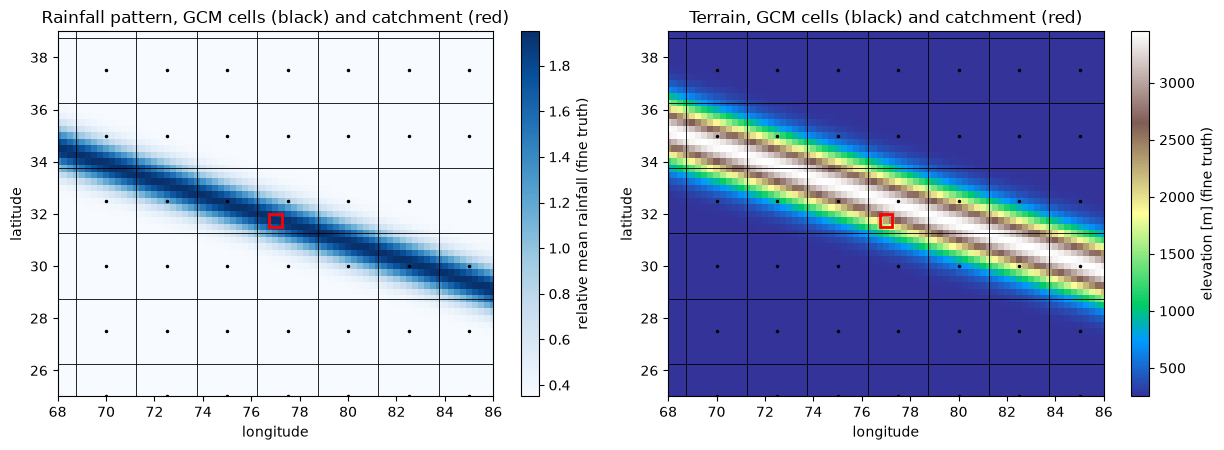

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
sub = fine.sel(lat=slice(25, 39), lon=slice(68, 86))
for ax, var, cmap, lab in zip(axs, ["rain_mult", "elev"], ["Blues", "terrain"],
                              ["relative mean rainfall (fine truth)", "elevation [m] (fine truth)"]):
    im = ax.pcolormesh(sub.lon, sub.lat, sub[var], cmap=cmap, shading="auto")
    plt.colorbar(im, ax=ax, label=lab)
    for x in np.arange(66.25, 88.8, 2.5): ax.axvline(x, color="k", lw=0.6)
    for y in np.arange(23.75, 41.3, 2.5): ax.axhline(y, color="k", lw=0.6)
    ax.plot(*np.meshgrid(glon, glat), "k.", ms=3)
    ax.add_patch(mpatches.Rectangle((LON0 - HALF, LAT0 - HALF), 2 * HALF, 2 * HALF, fc="none", ec="red", lw=2))
    ax.set_xlim(68, 86); ax.set_ylim(25, 39); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
axs[0].set_title("Rainfall pattern, GCM cells (black) and catchment (red)")
axs[1].set_title("Terrain, GCM cells (black) and catchment (red)")
fig.tight_layout()

cell = dict(lat_c=32.5, lon_c=77.5, half_lat=1.25, half_lon=1.25)          # the GCM cell that contains the catchment
print(f"catchment: relative rain {R_catch:.2f}, elevation {E_catch:.0f} m")
print(f"GCM cell : relative rain {float(box_mean(fine.rain_mult, **cell)):.2f} (cell mean), mean elevation of the cell {float(box_mean(fine.elev, **cell)):.0f} m")
print(f"GCM surface seen at the catchment (interpolated between cell centres): {float(gcm.orog.interp(lat=LAT0, lon=LON0)):.0f} m")

The cell-average rainfall factor (about 1.0) is far below the catchment's (1.84): the narrow wet slope is averaged with the dry land around it. The model's smooth surface at the catchment, after interpolation between cell centres, is also lower than the real catchment altitude, and a lower surface is warmer (about $6.5$ K per km). This is the scale part of the gap, and it exists even for a perfect model.

### 6.2 Subsetting to a catchment

Because the catchment is much smaller than a cell, the obvious `sel(lat=slice(...), lon=slice(...))` finds **no grid point at all**. There are three common ways to get a catchment series from a coarse grid:

- the **nearest cell** (`method="nearest"`): the value of the one cell that contains the catchment,
- **interpolation** (`interp`): a weighted mean of the four surrounding cell centres (bilinear), smoother,
- for a basin that spans several cells, a **latitude-weighted mean** over the cells that overlap it (weights $\cos\varphi$, proportional to cell area).

In [9]:
box = dict(lat=slice(LAT0 - HALF, LAT0 + HALF), lon=slice(LON0 - HALF, LON0 + HALF))
print("slice on the catchment box returns", gcm.sel(**box).pr.shape, "-> no grid point inside the box")

nearest = gcm.sel(lat=LAT0, lon=LON0, method="nearest")
interp = gcm.interp(lat=LAT0, lon=LON0)
print(f"nearest cell centre: lat {float(nearest.lat)}, lon {float(nearest.lon)}")
big = gcm.sel(lat=slice(29, 36), lon=slice(74, 80.5))                        # cells overlapping a larger basin
wmean = big.pr.weighted(np.cos(np.deg2rad(big.lat))).mean(("lat", "lon"))
for name, da in [("nearest cell", nearest.pr), ("bilinear interp", interp.pr), ("cos(lat)-weighted mean, 3x3 cells", wmean)]:
    x = da * 86400
    print(f"{name:35s} mean {float(x.mean()):.2f} mm/day   99th percentile {float(x.quantile(0.99)):.1f} mm/day")

slice on the catchment box returns (3600, 0, 0) -> no grid point inside the box
nearest cell centre: lat 32.5, lon 77.5
nearest cell                        mean 2.83 mm/day   99th percentile 33.6 mm/day
bilinear interp                     mean 2.49 mm/day   99th percentile 27.5 mm/day
cos(lat)-weighted mean, 3x3 cells   mean 1.81 mm/day   99th percentile 18.9 mm/day


The three results differ a great deal. The mean changes because the cells around the catchment are drier (the wet slope is narrow), and the daily extremes shrink the more cells are averaged, because their noise partly cancels. The extraction method is a real choice that affects both the mean and the heavy-rain statistics, so use the same one for the historical and the future series. Below we use the bilinear value for both the GCM and the reanalysis.

### 6.3 Units and calendars

GCM precipitation is a flux and temperature is in kelvin; the reanalysis precipitation is a depth in metres. Convert first, and update the `units` attribute so that nobody has to guess. Then the calendar: the GCM year has 360 days, the real year 365 or 366.

In [10]:
g_pt = gcm.interp(lat=LAT0, lon=LON0)            # model at the catchment
r_pt = rea.interp(lat=LAT0, lon=LON0)            # reanalysis at the catchment

gcm_pr = g_pt.pr * 86400                        # kg m-2 s-1 -> mm/day   (1 kg m-2 = 1 mm)
gcm_pr.attrs["units"] = "mm/day"
gcm_tas = g_pt.tas - 273.15; gcm_tas.attrs["units"] = "degC"
rea_pr = r_pt.tp * 1000                         # m -> mm
rea_tas = r_pt.t2m - 273.15
print("one monsoon day, raw flux 1.0e-4 kg m-2 s-1 ->", 1.0e-4 * 86400, "mm/day")
print("10 mm/day over 1000 km2 -> discharge", 10 * 1000 / 86.4, "m3/s")
print(f"mean GCM flux {float(g_pt.pr.mean()):.3e} kg m-2 s-1  = {float(gcm_pr.mean()):.2f} mm/day")

# ---- calendar
t = g_pt.time
print("\nGCM calendar:", t.dt.calendar, "| days per year:", t.size // len(YEARS))
print("first days of March 2001 are preceded by:", [str(d)[:10] for d in t.values[57:60]], "(Feb has 30 days)")
try:
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        t.to_index().to_datetimeindex()
except Exception as err:
    print("conversion to a normal date index fails:", type(err).__name__)

mean_rate = float(gcm_pr.mean())
annual = gcm_pr.groupby("time.year").sum()                                # sum of the model's own 360 days
print(f"annual total from the 360-day year : {float(annual.mean()):.0f} mm")
print(f"annual total if we wrongly use 365.25 days: {mean_rate * 365.25:.0f} mm   (+{(365.25 / 360 - 1) * 100:.1f} %)")

one monsoon day, raw flux 1.0e-4 kg m-2 s-1 -> 8.64 mm/day
10 mm/day over 1000 km2 -> discharge 115.74074074074073 m3/s
mean GCM flux 2.882e-05 kg m-2 s-1  = 2.49 mm/day

GCM calendar: 360_day | days per year: 360
first days of March 2001 are preceded by: ['2001-02-28', '2001-02-29', '2001-02-30'] (Feb has 30 days)
conversion to a normal date index fails: ValueError
annual total from the 360-day year : 896 mm
annual total if we wrongly use 365.25 days: 910 mm   (+1.5 %)


A rate in mm/day does not depend on the calendar, but a **total** does: monthly and annual totals, and flow volumes, must use the number of days of the calendar of the data (30 per month here). To compare with observations **day by day**, match dates, not row numbers: the 360-day calendar has a 29 and a 30 February that the real calendar does not (they have no counterpart, and the 31st of seven months has none in the model). For monthly or seasonal comparisons, group by month and the problem disappears.

### 6.4 Comparing GCM, reanalysis and observation

Now put the three series for the catchment side by side. We compare the **monthly climatology** (calendar-independent), a **monsoon season** day by day, the **distribution** of daily rain (exceedance probability), and the **day-by-day agreement** (matching by date).

GCM days with no real-calendar date: 18 of 3600


daily correlation with the observation, matched by date:


  raw          : reanalysis 0.82   GCM 0.20   (the GCM value is the shared seasonal cycle)
  seasonal cycle removed: reanalysis 0.77   GCM 0.02


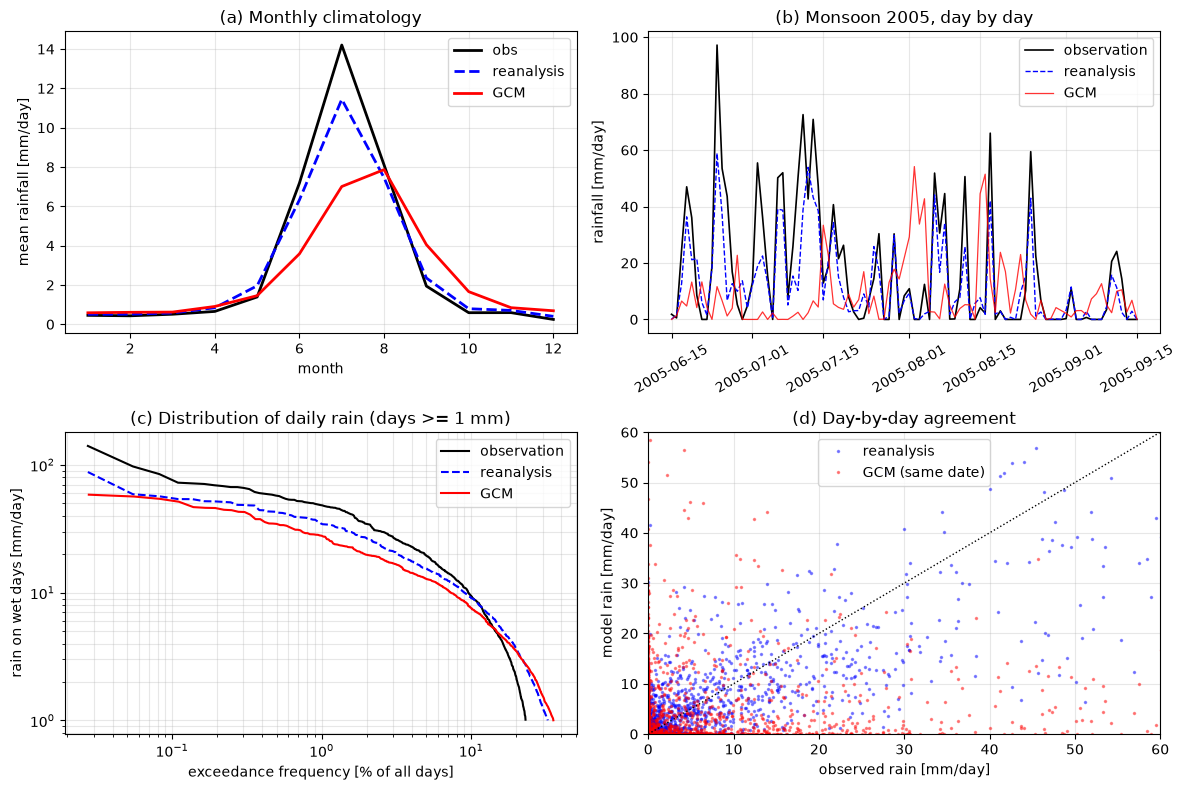

In [11]:
obs_pr, obs_tas = obs["obs_pr_mm"], obs["obs_tas_C"]
rea_pr_s = pd.Series(rea_pr.values, index=t_std)
rea_tas_s = pd.Series(rea_tas.values, index=t_std)
# the GCM series carries (year, month, day) of its own calendar; real dates exist for most days
g_df = pd.DataFrame({"year": t.dt.year.values, "month": t.dt.month.values, "day": t.dt.day.values,
                     "pr": gcm_pr.values, "tas": gcm_tas.values})
g_df["date"] = pd.to_datetime(g_df[["year", "month", "day"]], errors="coerce")     # NaT: 29/30 Feb that do not exist
print("GCM days with no real-calendar date:", int(g_df.date.isna().sum()), "of", len(g_df))
g_real = g_df.dropna(subset=["date"]).set_index("date")

# 1) monthly climatology, calendar-independent
clim = pd.DataFrame({"obs": obs_pr.groupby(obs_pr.index.month).mean(),
                     "reanalysis": rea_pr_s.groupby(rea_pr_s.index.month).mean(),
                     "GCM": g_df.groupby("month").pr.mean()})
clim.index.name = "month"

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
ax = axs[0, 0]
for c, st in zip(clim.columns, ["k-", "b--", "r-"]): ax.plot(clim.index, clim[c], st, lw=2, label=c)
ax.set_xlabel("month"); ax.set_ylabel("mean rainfall [mm/day]"); ax.set_title("(a) Monthly climatology"); ax.legend(); ax.grid(alpha=0.3)

ax = axs[0, 1]
season = slice("2005-06-15", "2005-09-15")
ax.plot(obs_pr[season], "k", lw=1.2, label="observation")
ax.plot(rea_pr_s[season], "b--", lw=1, label="reanalysis")
ax.plot(g_real.pr[season], "r", lw=0.9, alpha=0.8, label="GCM")
ax.set_ylabel("rainfall [mm/day]"); ax.set_title("(b) Monsoon 2005, day by day"); ax.legend(); ax.grid(alpha=0.3)
ax.tick_params(axis="x", rotation=30)

ax = axs[1, 0]
for x, st, lab in [(obs_pr.values, "k-", "observation"), (rea_pr_s.values, "b--", "reanalysis"), (g_df.pr.values, "r-", "GCM")]:
    w = np.sort(x[x >= 1])[::-1]
    ax.plot(np.arange(1, w.size + 1) / (x.size + 1) * 100, w, st, label=lab, lw=1.5)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("exceedance frequency [% of all days]"); ax.set_ylabel("rain on wet days [mm/day]")
ax.set_title("(c) Distribution of daily rain (days >= 1 mm)"); ax.legend(); ax.grid(alpha=0.3, which="both")

ax = axs[1, 1]
cmp = pd.DataFrame({"obs": obs_pr}).join(pd.DataFrame({"rea": rea_pr_s})).join(g_real.pr.rename("gcm"), how="left")
ax.plot(cmp.obs, cmp.rea, "b.", ms=3, alpha=0.4, label="reanalysis")
ax.plot(cmp.obs, cmp.gcm, "r.", ms=3, alpha=0.4, label="GCM (same date)")
ax.plot([0, 60], [0, 60], "k:", lw=1)
ax.set_xlim(0, 60); ax.set_ylim(0, 60); ax.set_xlabel("observed rain [mm/day]"); ax.set_ylabel("model rain [mm/day]")
ax.set_title("(d) Day-by-day agreement"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
def anomaly(x):                                   # remove each series' own monthly climatology (the shared seasonal cycle)
    return x - x.groupby(x.index.month).transform("mean")
an = cmp.apply(anomaly)
print("daily correlation with the observation, matched by date:")
print(f"  raw          : reanalysis {cmp.obs.corr(cmp.rea):.2f}   GCM {cmp.obs.corr(cmp.gcm):.2f}   (the GCM value is the shared seasonal cycle)")
print(f"  seasonal cycle removed: reanalysis {an.obs.corr(an.rea):.2f}   GCM {an.obs.corr(an.gcm):.2f}")

Reading the figure:

- **(a)** The GCM's monsoon is late and weak: too little in July, too much in September to November (a late and lingering monsoon is a common model bias). The reanalysis follows the observed seasonal cycle, although it too is a little smoothed.
- **(b)** The reanalysis rises and falls with the real storms; the GCM produces its own storms on other days. This is the *timing* part of the gap.
- **(c)** The GCM has too many light rain days and too few heavy ones: its curve lies below the observation at the extreme end. A flood study using raw GCM rain would underestimate design events.
- **(d)** The reanalysis points cluster around the 1:1 line (but spread widely), the GCM points are a cloud. Matching the dates gives a small positive correlation only because both series have a monsoon season; once each series' own monthly climatology is removed the correlation is essentially zero. A free-running model cannot be compared day by day, only statistically.

The next cell collects the statistics that the spreadsheet `Compare` also contains.

In [12]:
def describe(x, thr=1.0):
    x = np.asarray(x)
    return {"mean [mm/day]": x.mean(), "std [mm/day]": x.std(ddof=1), "wet-day fraction": (x >= thr).mean(),
            "mean wet-day intensity [mm/day]": x[x >= thr].mean(), "95th percentile [mm/day]": np.percentile(x, 95),
            "99th percentile [mm/day]": np.percentile(x, 99), "maximum [mm/day]": x.max()}
st = pd.DataFrame({"obs": describe(obs_pr), "reanalysis": describe(rea_pr_s), "GCM": describe(g_df.pr)})
st["reanalysis/obs"] = st.reanalysis / st.obs
st["GCM/obs"] = st.GCM / st.obs
print(st.round(2).to_string())

ann_obs = obs_pr.sum() / len(YEARS); ann_gcm = g_df.pr.sum() / len(YEARS); ann_rea = rea_pr_s.sum() / len(YEARS)
print(f"\nannual rainfall [mm]: obs {ann_obs:.0f}, reanalysis {ann_rea:.0f}, GCM {ann_gcm:.0f}  (GCM/obs = {ann_gcm / ann_obs:.2f}, own 360 days)")

# temperature: how much of the bias is just altitude?
Z_gcm, Z_rea = float(g_pt.orog), float(r_pt.z)
for name, tas_, Z in [("reanalysis", rea_tas.values, Z_rea), ("GCM", gcm_tas.values, Z_gcm)]:
    bias = tas_.mean() - obs_tas.mean()
    lapse_part = 6.5 * (E_catch - Z) / 1000
    print(f"{name:10s} temperature bias {bias:+.2f} K; expected from altitude alone (6.5 K/km x {E_catch - Z:.0f} m) {lapse_part:+.2f} K; residual {bias - lapse_part:+.2f} K")

                                    obs  reanalysis    GCM  reanalysis/obs  GCM/obs
mean [mm/day]                      3.05        2.84   2.49            0.93     0.82
std [mm/day]                       9.03        6.77   5.46            0.75     0.60
wet-day fraction                   0.23        0.32   0.35            1.41     1.53
mean wet-day intensity [mm/day]   13.14        8.57   6.77            0.65     0.52
95th percentile [mm/day]          19.39       15.41  12.81            0.79     0.66
99th percentile [mm/day]          47.91       34.29  27.47            0.72     0.57
maximum [mm/day]                 140.62       87.90  58.44            0.63     0.42

annual rainfall [mm]: obs 1114, reanalysis 1039, GCM 896  (GCM/obs = 0.80, own 360 days)
reanalysis temperature bias +1.96 K; expected from altitude alone (6.5 K/km x 254 m) +1.65 K; residual +0.31 K
GCM        temperature bias +2.55 K; expected from altitude alone (6.5 K/km x 528 m) +3.43 K; residual -0.88 K


Two conclusions. **Rain:** the model is too dry by the annual total (about one fifth), which hides a bigger problem of distribution (a wet-day fraction that is too high and heavy rain that is too weak) and of timing (a late monsoon). One scale factor cannot repair all three; this is what bias correction methods (Lecture 18) address, and what weather generators (Lecture 21) reproduce explicitly. **Temperature:** most of the raw bias is the altitude difference between the model surface and the catchment, which can be removed with a lapse rate before anything statistical is done; the remainder is the model's own error.

### 6.5 Does the notebook match the spreadsheet?

The CSV files in `data/downscaling/lec16/` were written from the series above, and the spreadsheet `lec16_worked_examples.xlsx` computes the same statistics with live formulas (units, monthly climatology, calendar-aware totals, the table of statistics and the decision checklist). The cell below confirms that the files hold the same numbers as the series in this notebook and prints a few values to compare with the sheet.

In [13]:
base = "data/downscaling/lec16/"
url = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec16/"
def read(name):
    try:
        return pd.read_csv(base + name)
    except FileNotFoundError:                      # e.g. Colab without the repository
        return pd.read_csv(url + name)
try:
    c1, c2 = read("lec16_obs_reanalysis_daily.csv"), read("lec16_gcm_360day_daily.csv")
    same = (np.allclose(c1.obs_pr_mm_day, obs_pr, rtol=1e-6, atol=1e-9) and np.allclose(c1.rea_tp_m * 1000, rea_pr_s, rtol=1e-6, atol=1e-9)
            and np.allclose(c2.gcm_pr_kg_m2_s * 86400, g_df.pr, rtol=1e-6, atol=1e-9)
            and np.allclose(c2.gcm_tas_K - 273.15, g_df.tas, rtol=1e-6, atol=1e-6))
    print("CSV series equal the series of this notebook:", same)
except Exception as err:
    print("CSV files not available, skipping the comparison:", type(err).__name__)

print("\nvalues to compare with the workbook (sheet Compare):")
print(f"  annual GCM total, 360-day year (D23): {mean_rate * 360:.1f} mm     with 365.25 days (D22): {mean_rate * 365.25:.1f} mm")
print(f"  mean daily rain obs / reanalysis / GCM (B29:D29): {obs_pr.mean():.3f} / {rea_pr_s.mean():.3f} / {g_df.pr.mean():.3f}")
print(f"  wet-day fraction (B31:D31): {(obs_pr >= 1).mean():.3f} / {(rea_pr_s >= 1).mean():.3f} / {(g_df.pr >= 1).mean():.3f}")
print(f"  correlation obs vs reanalysis (B40): {obs_pr.corr(rea_pr_s):.3f}")
print(f"  mean temperature obs / reanalysis / GCM (B36:D36): {obs_tas.mean():.2f} / {rea_tas.values.mean():.2f} / {gcm_tas.values.mean():.2f} degC")

CSV series equal the series of this notebook: True

values to compare with the workbook (sheet Compare):
  annual GCM total, 360-day year (D23): 896.5 mm     with 365.25 days (D22): 909.5 mm
  mean daily rain obs / reanalysis / GCM (B29:D29): 3.050 / 2.845 / 2.490
  wet-day fraction (B31:D31): 0.231 / 0.325 / 0.354
  correlation obs vs reanalysis (B40): 0.823
  mean temperature obs / reanalysis / GCM (B36:D36): 10.29 / 12.25 / 12.84 degC


## Summary

- A GCM cell (1&ndash;2.5&deg;, tens of thousands of km$^2$) averages over terrain a catchment resolves. The gap has three parts: **scale** (cell mean $\ne$ catchment value), **bias** (the model's climate is wrong) and **timing** (a free-running model does not reproduce real days). The cell area is $A=R^2\Delta\lambda(\sin\varphi_2-\sin\varphi_1)$.
- **GCM** (free-running, future), **reanalysis** (assimilates observations, so it follows real weather), **RCM** (fine, nested, still biased) and **observations** (the target) play different roles. Check units (kg m$^{-2}$ s$^{-1}$ $\times$ 86 400 = mm/day; K $-$ 273.15; metres $\times$ 1000) and the **calendar** (360-day, noleap, standard) before comparing anything.
- Downscaling is **dynamical** (RCM) or **statistical**: bias correction and delta change, regression, weather generator, weather typing, and the refinements **temporal** and **spatial** downscaling.
- **Perfect prognosis** fits on reanalysis predictors and assumes the GCM predictors are as good; **model-output statistics** fits on the GCM output itself, so it can only match distributions.
- All statistical methods assume **stationarity**; a model that damps the climate response makes a constant correction miss $(1-s)\Delta T$.
- The choice of scheme follows from what the impact model needs (change only, distribution, sequence, many realisations, circulation link, sub-daily or gridded output).

## Check your understanding

1. A $2^\circ\times2^\circ$ cell is centred at $30^\circ$N. Compute its area and the percentage covered by a 3000 km$^2$ catchment. Is the catchment resolved by the model?
2. A model gives $pr=2.3\times10^{-5}$ kg m$^{-2}$ s$^{-1}$ for a 30-day month. Give the daily rate in mm/day and the monthly total in mm. What would you get if you wrongly used 31 days?
3. Why is the day-to-day correlation between a free-running GCM and a rain gauge about zero, and why is that not a defect of the model? Which of the data types in Section 2 would you use to fit a regression?
4. A model's response to warming is 70 % of the local response ($s=0.7$) and the true local warming is 4 K. What does a mean-shift bias correction project, and what is the error?
5. For each project choose a scheme with the decision guide: (a) hourly design storms for a 20 km$^2$ urban catchment, (b) change in mean annual flow of a reservoir catchment by 2100, (c) the probability of three successive failed monsoons.

# 7) Try it yourself

- Change the seed in the generator (`default_rng(16)`) and rerun: how stable are the bias numbers of Section 6.4 over 10 years?
- Compare `nearest`, `interp` and the cell-mean weighted series for the 99th percentile and the annual total. Which would you choose, and why must the same choice be used for the future?
- Apply the lapse-rate correction $T_\mathrm{corr}=T_\mathrm{gcm}+6.5\,(Z_\mathrm{gcm}-Z_\mathrm{catch})/1000$ and recompute the temperature bias.
- In the spreadsheet, change the wet-day threshold on `Compare` from 1 mm to 0.1 mm and watch the wet-day fractions; then answer the cases on `Method_guide` and add your own project in the last row.
- Paste real data (IMD rainfall, ERA5 or a NEX-GDDP-CMIP6 series) into the `Data` sheet and look for the same three symptoms: scale, bias, timing.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The concepts follow the introductory and data chapters of the reference book below; the explanations, derivations, synthetic data, code and figures here are our own.

**Main reference.** Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press. Chapter 1 (Sections 1.1&ndash;1.4: why downscale, climate models, the three statistical families, selecting a scheme) and Chapter 3 (Sections 3.1&ndash;3.3: GCM, reanalysis and RCM data and their formats). The decision guide and the perfect-prognosis versus model-output-statistics discussion, the units and calendar sections and the stationarity derivation were developed for this course.

**Further reading.**
Maraun, D., et al. (2010). Precipitation downscaling under climate change: Recent developments to bridge the gap between dynamical models and the end user. *Reviews of Geophysics, 48*, RG3003. &middot; Maraun, D., & Widmann, M. (2018). *Statistical Downscaling and Bias Correction for Climate Research*. Cambridge University Press. &middot; Wilby, R. L., & Wigley, T. M. L. (1997). Downscaling general circulation model output: a review of methods and limitations. *Progress in Physical Geography, 21*, 530&ndash;548. &middot; Eyring, V., et al. (2016). Overview of CMIP6 experimental design and organization. *Geoscientific Model Development, 9*, 1937&ndash;1958. &middot; Hersbach, H., et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society, 146*, 1999&ndash;2049.

All data in this lecture are synthetic and generated in Section 6; the catchment, its altitude and the model biases are illustrative, not a real basin or model. To use real data replace the series by IMD gridded rainfall (observations), ERA5 (reanalysis) and a CMIP6 or NEX-GDDP-CMIP6 file (model). Resolution values are typical orders of magnitude. The spreadsheet formulas were checked against an independent Python calculation of the same chains but not recalculated in desktop Excel here. All figures are drawn for this course.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```